In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT y enumere todas sus rutas entre el nodo inicial y el final.  "
pregunta_2 = "2. Construya la matriz de caminos del proyecto (una fila por ruta, una columna por actividad).  "
pregunta_3 = "3. Calcule la duración de cada ruta como producto de la matriz de caminos por el vector de duraciones, y la duración del proyecto como el máximo. Identifique la ruta crítica.  "
pregunta_4 = "4. Calcule la sensibilidad de la duración del proyecto a cada actividad: ¿en cuánto aumenta la duración si una actividad dura un día más? ¿Y si dura un día menos?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y enumere todas sus rutas entre el nodo inicial y el final.  

2. Construya la matriz de caminos del proyecto (una fila por ruta, una columna por actividad).  

3. Calcule la duración de cada ruta como producto de la matriz de caminos por el vector de duraciones, y la duración del proyecto como el máximo. Identifique la ruta crítica.  

4. Calcule la sensibilidad de la duración del proyecto a cada actividad: ¿en cuánto aumenta la duración si una actividad dura un día más? ¿Y si dura un día menos?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 8       ),
    ('B'     , '---'      , 4       ),
    ('C'     , 'A,B'      , 7       ),
    ('D'     , 'C'        , 1       ),
    ('E'     , 'C'        , 5       ),
    ('F'     , 'D'        , 3       ),
    ('G'     , 'F'        , 5       ),
    ('H'     , 'D,E'      , 8       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,8
B,---,4
C,"A,B",7
D,C,1
E,C,5
F,D,3
G,F,5
H,"D,E",8


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
    'H': 'Rodaje en plató',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores
H,Rodaje en plató


# Resolución

In [7]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y enumere todas sus rutas entre el nodo inicial y el final.  

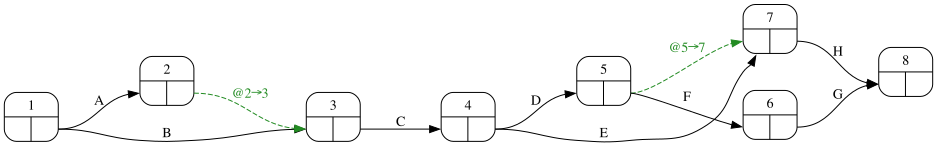

In [10]:
#| fig-cap: "Grafo PERT con numeración de nodos"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

Las rutas se enumeran recorriendo el grafo desde el nodo inicial: en cada nodo se abre una rama por cada arco saliente. Las ficticias se recorren pero no se anotan.

In [11]:
#| tbl-cap: "Rutas del proyecto"
#| label: tbl-rutas
rutas = proyecto.paths(dummies=False)
pd.Series({r: ' - '.join(a) for r, a in rutas.items()}).to_frame('actividades')

,actividades
Route_1,A - C - D - F - G
Route_2,A - C - D - H
Route_3,A - C - E - H
Route_4,B - C - D - F - G
Route_5,B - C - D - H
Route_6,B - C - E - H


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Construya la matriz de caminos del proyecto (una fila por ruta, una columna por actividad).  

In [13]:
#| tbl-cap: "Matriz de caminos"
#| label: tbl-matrizCaminos
path_matrix = proyecto.path_matrix(dummies=False)
proyecto.display_rutas("pert")

,A,B,C,D,E,F,G,H
Route_1,1,0,1,1,0,1,1,0
Route_2,1,0,1,1,0,0,0,1
Route_3,1,0,1,0,1,0,0,1
Route_4,0,1,1,1,0,1,1,0
Route_5,0,1,1,1,0,0,0,1
Route_6,0,1,1,0,1,0,0,1


## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Calcule la duración de cada ruta como producto de la matriz de caminos por el vector de duraciones, y la duración del proyecto como el máximo. Identifique la ruta crítica.  

In [15]:
duraciones = datos_proyecto['duration'][path_matrix.columns]
duraciones_rutas = path_matrix @ duraciones
Math(bmatrix(path_matrix) + r' \times ' + bmatrix(duraciones) + ' = ' + bmatrix(duraciones_rutas))

<IPython.core.display.Math object>

In [16]:
#| tbl-cap: "Duración de cada ruta, sumando sus actividades"
#| label: tbl-rutasPaso-b
detalle_rutas(path_matrix, duraciones)

,actividades,duración = suma,duración
Route_1,A - C - D - F - G,A(8) + C(7) + D(1) + F(3) + G(5) = 24,24.0
Route_2,A - C - D - H,A(8) + C(7) + D(1) + H(8) = 24,24.0
Route_3,A - C - E - H,A(8) + C(7) + E(5) + H(8) = 28,28.0
Route_4,B - C - D - F - G,B(4) + C(7) + D(1) + F(3) + G(5) = 20,20.0
Route_5,B - C - D - H,B(4) + C(7) + D(1) + H(8) = 20,20.0
Route_6,B - C - E - H,B(4) + C(7) + E(5) + H(8) = 24,24.0


In [17]:
duracion_proyecto = int(duraciones_rutas.max())
ruta_critica = duraciones_rutas.idxmax()
Markdown(f'La duración del proyecto es {duracion_proyecto} días, la de la ruta más larga, {ruta_critica}: '
         f'{" - ".join(rutas[ruta_critica])}. Coincide con el tiempo más temprano del último nodo: {proyecto.duration(duraciones)}.')

La duración del proyecto es 28 días, la de la ruta más larga, Route_3: A - C - E - H. Coincide con el tiempo más temprano del último nodo: 28.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Calcule la sensibilidad de la duración del proyecto a cada actividad: ¿en cuánto aumenta la duración si una actividad dura un día más? ¿Y si dura un día menos?  

La duración del proyecto es $\tau = \max_r (P\,d)_r$. Si una actividad crítica dura un día más, la ruta crítica se alarga un día y con ella el proyecto: su sensibilidad es 1. Si una actividad no crítica dura un día más, la ruta más larga no cambia mientras no se agote la holgura: sensibilidad 0. Al acortar una actividad crítica el proyecto sólo se acorta hasta que otra ruta pasa a ser la más larga.

In [19]:
sensibilidad = proyecto.tau_sensitivity(duraciones.to_dict())
holgura = duracion_proyecto - duraciones_rutas
segunda = holgura[holgura > 0].min() if (holgura > 0).any() else None
pd.DataFrame({'sensibilidad (+1 día)': sensibilidad.reindex(duraciones.index)}).T

,A,B,C,D,E,F,G,H
sensibilidad (+1 día),1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [20]:
comprobacion = {}
for act in duraciones.index:
    mas = duraciones.copy(); mas[act] += 1
    menos = duraciones.copy(); menos[act] -= 1
    comprobacion[act] = {'+1 día': int((path_matrix @ mas).max()) - duracion_proyecto,
                         '-1 día': int((path_matrix @ menos).max()) - duracion_proyecto}
pd.DataFrame(comprobacion)

,A,B,C,D,E,F,G,H
+1 día,1,0,1,0,1,0,0,1
-1 día,-1,0,-1,0,-1,0,0,-1


In [21]:
Markdown(f'Al acortar una actividad crítica el proyecto se reduce un día sólo si ninguna otra ruta alcanza la duración máxima; '
         f'la segunda ruta más larga está a {segunda} día(s) de la crítica, así que esa es la reducción máxima que puede conseguirse '
         'acortando una única actividad crítica que no pertenezca también a esa segunda ruta.')

Al acortar una actividad crítica el proyecto se reduce un día sólo si ninguna otra ruta alcanza la duración máxima; la segunda ruta más larga está a 4 día(s) de la crítica, así que esa es la reducción máxima que puede conseguirse acortando una única actividad crítica que no pertenezca también a esa segunda ruta.